In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-darkgrid')

file_path = '../data/raw/pvdaq_system10_2019_2023_combined.csv'

df = pd.read_csv(file_path)

print(f"Initial shape: {df.shape[0]} rows, {df.shape[1]} columns")

Initial shape: 1988017 rows, 17 columns


In [3]:
missing_counts = df.isnull().sum()

missing_percentage = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_counts, 
    'Percentage (%)': missing_percentage.round(2)
})

print(missing_df[missing_df['Missing Values'] > 0])

                          Missing Values  Percentage (%)
ac_power__423                       4534            0.23
ac_voltage__426                     4007            0.20
das_temp__433                       4967            0.25
dc_pos_voltage__424                 4380            0.22
dc_power__422                       3836            0.19
module_temp_1__429                 10190            0.51
module_temp_3__431                 10437            0.52
poa_irradiance__421                87439            4.40
module_temp_2__430                 10436            0.52
inverter_temp__432                 10451            0.53
dc_pos_current__425                 4974            0.25
ac_current__427                     4980            0.25
ambient_temp__428                   4983            0.25
das_battery_voltage__434            4975            0.25


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-darkgrid')

file_path = '../data/raw/pvdaq_system10_2019_2023_combined.csv'

df = pd.read_csv(file_path, parse_dates=['measured_on'])


In [5]:
col_map = {
    'measured_on': 'timestamp',
    'dc_pos_voltage__424': 'v_dc',
    'dc_pos_current__425': 'i_dc',
    'poa_irradiance__421': 'irradiance',
    'ambient_temp__428': 'temp_ambient'
}

df_clean = df.rename(columns=col_map)

cols_to_keep = ['timestamp', 'v_dc', 'i_dc', 'irradiance', 'temp_ambient']
df_clean = df_clean[cols_to_keep]


In [6]:
df_clean = df_clean.dropna()

# 2. Filtering for daylight hours (7 AM to 6 PM) so the model does not train on darkness
df_day = df_clean[(df_clean['timestamp'].dt.hour >= 7) & (df_clean['timestamp'].dt.hour <= 18)].copy()

# 3. Filtering out times when the inverter was off despite the sun being up
df_day = df_day[df_day['irradiance'] > 10]

print(f"We have {len(df_day)} daylight rows now.")

We have 837054 daylight rows now.


In [7]:
processed_path = '../data/processed/clean_daylight_data.csv'

df_day.to_csv(processed_path, index=False)


Markdown

### Data Visualization

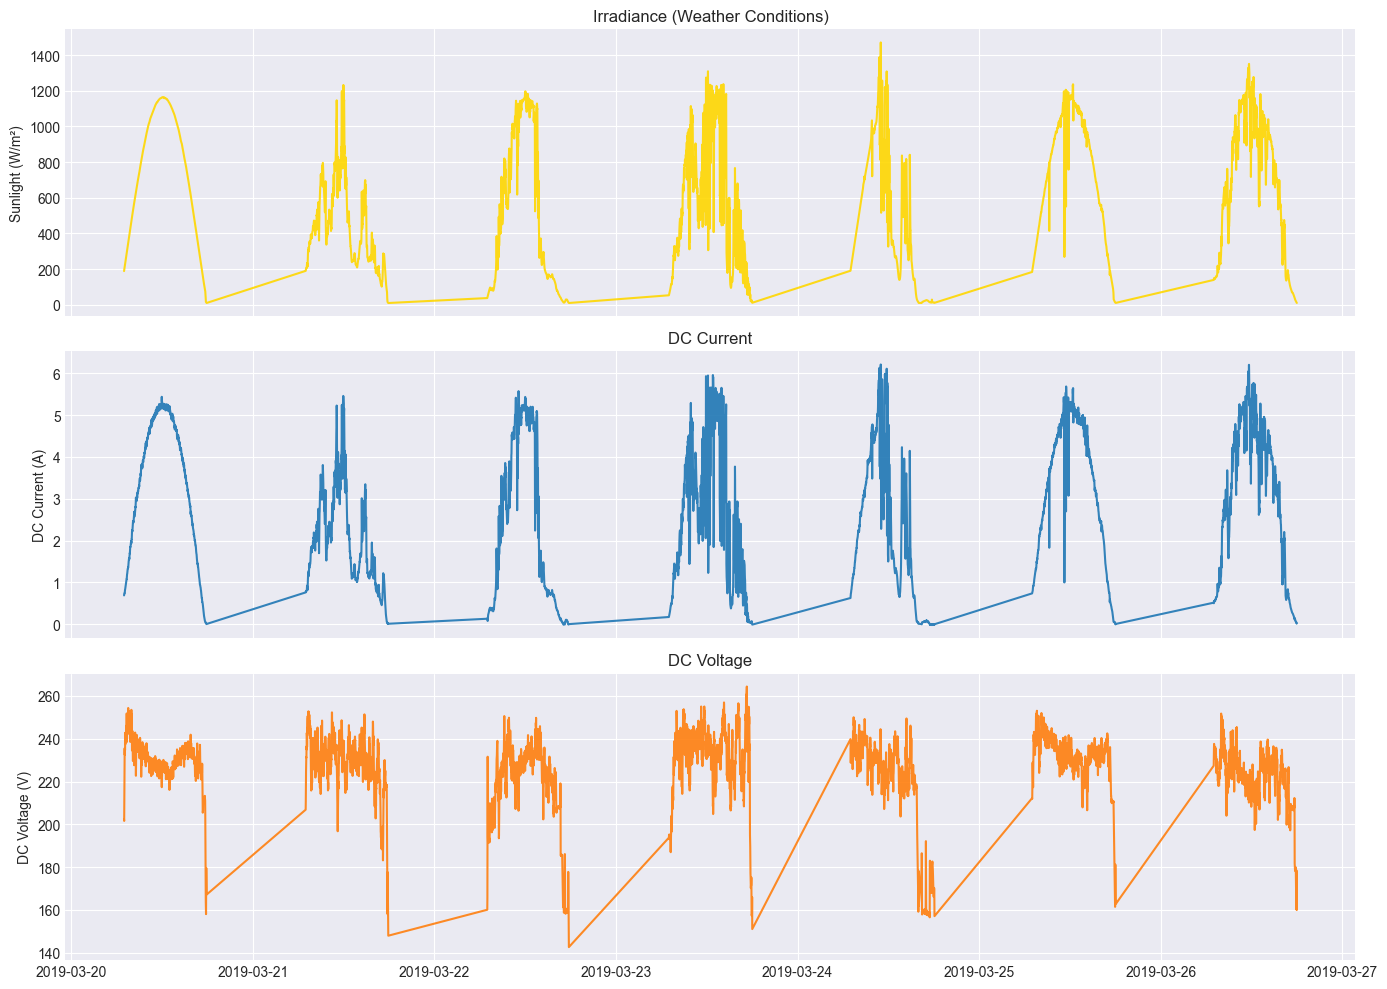

In [9]:
df_day = df_day.sort_values('timestamp')

# taking just the first 7 days
start_date = df_day['timestamp'].min()
end_date = start_date + pd.Timedelta(days=7)

# Creating a smaller dataframe for just this one week
week_data = df_day[(df_day['timestamp'] >= start_date) & (df_day['timestamp'] < end_date)]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Plotting Irradiance 
ax1.plot(week_data['timestamp'], week_data['irradiance'], color='gold', alpha=0.9)
ax1.set_ylabel('Sunlight (W/m²)')
ax1.set_title('Irradiance (Weather Conditions)')

# Plotting DC Current
ax2.plot(week_data['timestamp'], week_data['i_dc'], color='tab:blue', alpha=0.9)
ax2.set_ylabel('DC Current (A)')
ax2.set_title('DC Current')

# Plotting DC Voltage
ax3.plot(week_data['timestamp'], week_data['v_dc'], color='tab:orange', alpha=0.9)
ax3.set_ylabel('DC Voltage (V)')
ax3.set_title('DC Voltage')

plt.tight_layout()
plt.show()

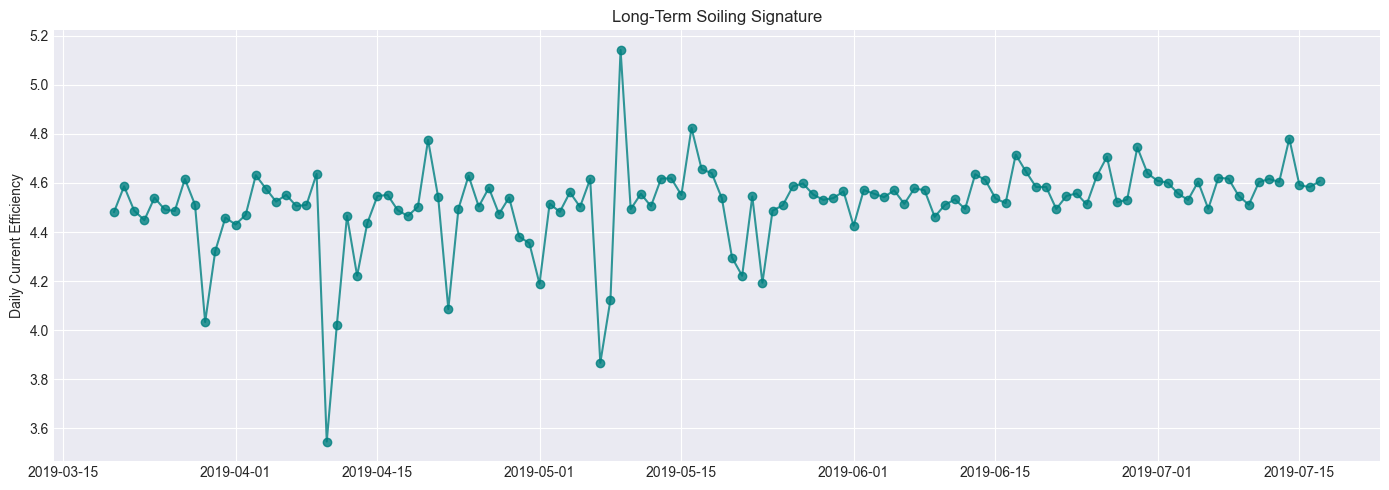

In [10]:
df_eff = df_day.copy()

# Calculating instantaneous efficiency proxy (Current / Sunlight)
# I multiplied by 1000 just to scale the numbers to a readable range
df_eff['current_efficiency'] = (df_eff['i_dc'] / df_eff['irradiance']) * 1000

daily_eff = df_eff.set_index('timestamp').resample('D')['current_efficiency'].median().dropna()

months_data = daily_eff.head(120)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(months_data.index, months_data.values, marker='o', linestyle='-', color='teal', alpha=0.8)
ax.set_ylabel('Daily Current Efficiency')
ax.set_title('Long-Term Soiling Signature')

plt.tight_layout()
plt.show()